Iris Flower Classification: Multi-Model Benchmarking Pipeline

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

In [4]:
df.head(10)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [5]:
df.shape

(150, 5)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [7]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Exploratory Data Analysis (EDA)

In this section, we examine the dataset's structure, data quality, class distribution, and relationships between numerical features before training the classification models.

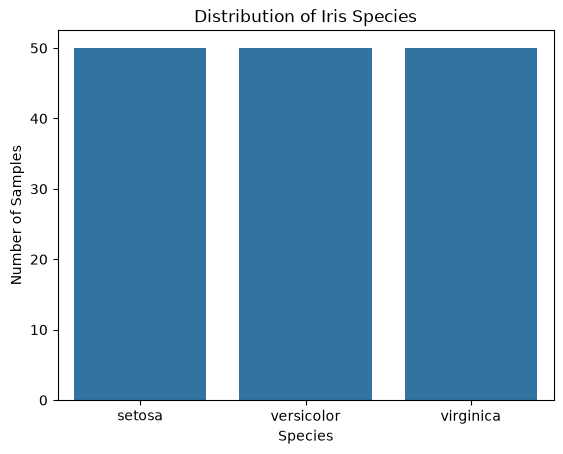

In [10]:
sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.show()

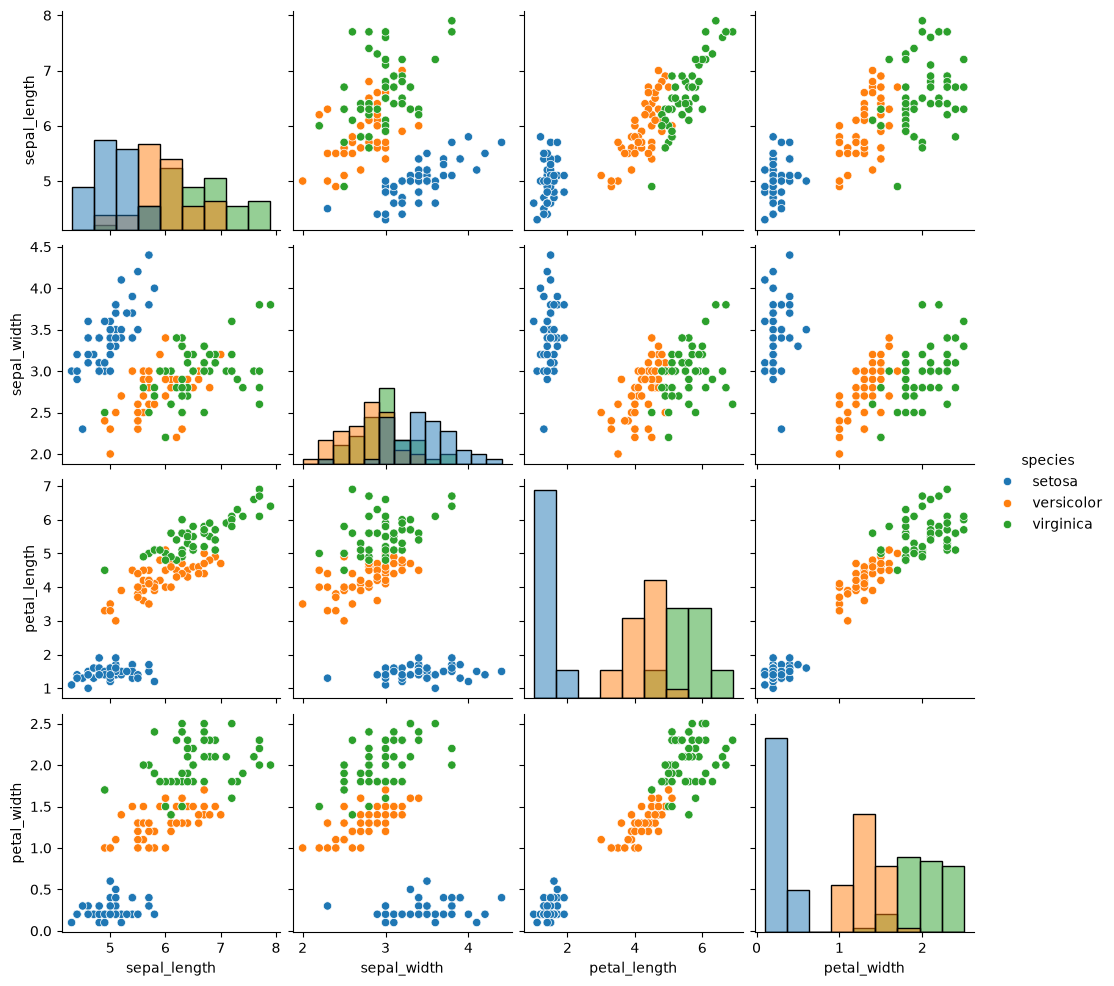

In [11]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.show()

In [12]:
df[df.duplicated(keep=False)]

,sepal_length,sepal_width,petal_length,petal_width,species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


In [13]:
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())

Dataset shape: (149, 5)
Duplicate rows remaining: 0


In [14]:
# Compare the average feature measurements by species
df.groupby("species").mean(numeric_only=True).round(2)

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.60,2.98,5.56,2.03


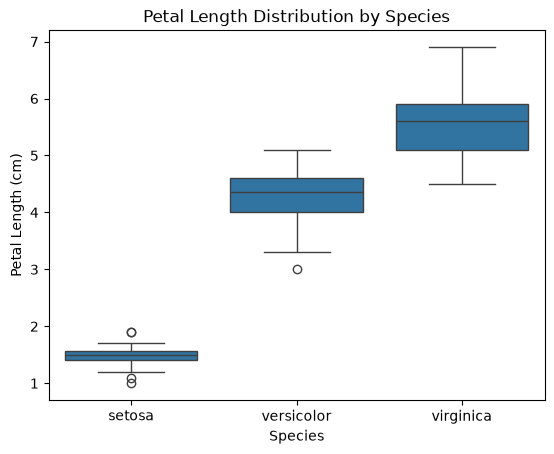

In [15]:
# Compare the spread of petal length across species
sns.boxplot(data=df, x="species", y="petal_length")

plt.title("Petal Length Distribution by Species")
plt.xlabel("Species")
plt.ylabel("Petal Length (cm)")
plt.show()

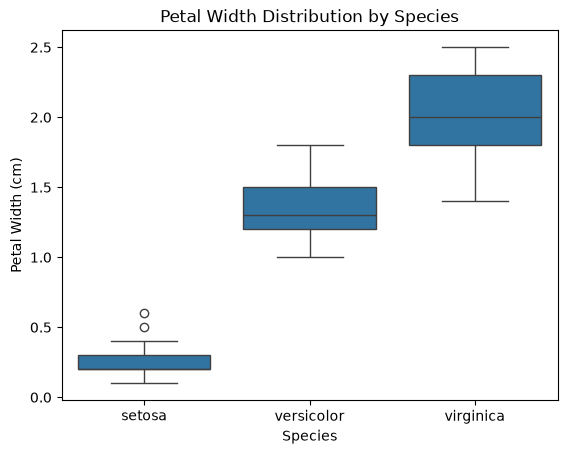

In [16]:
sns.boxplot(data=df, x="species", y="petal_width")

plt.title("Petal Width Distribution by Species")
plt.xlabel("Species")
plt.ylabel("Petal Width (cm)")
plt.show()

Training and Testing

In [17]:
x = df.drop(columns=["species"])
y = df["species"]

print("Features:")
print(x.head())

print("\nTarget:")
print(y.head())


Features:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Target:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str


In [18]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (119, 4)
Testing features: (30, 4)
Training labels: (119,)
Testing labels: (30,)


In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [20]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [21]:
logistic_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may n

In [22]:
y_pred_lr = logistic_model.predict(x_test)

print("Actual labels:")
print(y_test.values)

print("\nPredicted labels:")
print(y_pred_lr)

Actual labels:
<StringArray>
['versicolor', 'versicolor',  'virginica',     'setosa',  'virginica',
 'versicolor', 'versicolor',     'setosa',  'virginica',  'virginica',
     'setosa',     'setosa',     'setosa', 'versicolor',  'virginica',
     'setosa', 'versicolor',     'setosa',  'virginica',     'setosa',
 'versicolor',  'virginica',     'setosa',     'setosa', 'versicolor',
 'versicolor',  'virginica',  'virginica',  'virginica', 'versicolor']
Length: 30, dtype: str

Predicted labels:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica' 'setosa' 'setosa' 'setosa'
 'versicolor' 'virginica' 'setosa' 'virginica' 'setosa' 'virginica'
 'setosa' 'versicolor' 'versicolor' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'virginica' 'virginica' 'versicolor']


In [23]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))


Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



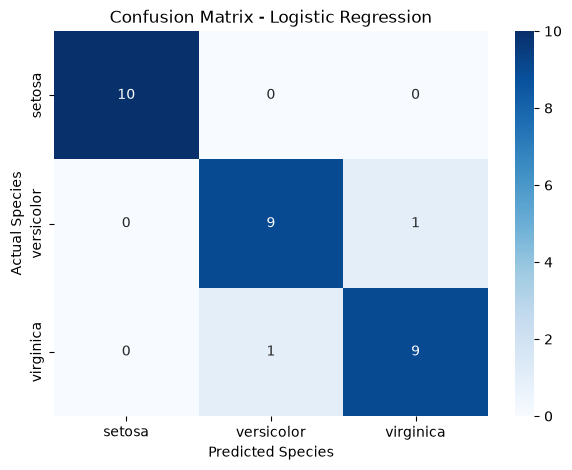

In [24]:
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=["setosa", "versicolor", "virginica"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["setosa", "versicolor", "virginica"],
    yticklabels=["setosa", "versicolor", "virginica"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

Second model — Decision Tree

In [25]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(x_train, y_train)

y_pred_tree = tree_model.predict(x_test)

In [26]:
print("Accuracy:", accuracy_score(y_test, y_pred_tree))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



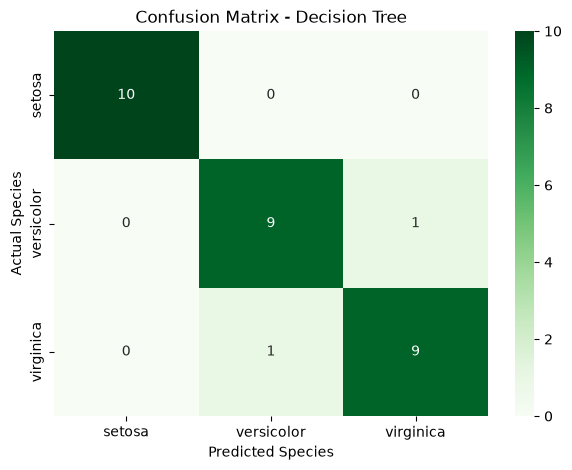

In [27]:
cm_tree = confusion_matrix(
    y_test,
    y_pred_tree,
    labels=["setosa", "versicolor", "virginica"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["setosa", "versicolor", "virginica"],
    yticklabels=["setosa", "versicolor", "virginica"]
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_tree
}

results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro"
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro"
        ),
        "F1-score (Macro)": f1_score(
            y_test, predictions, average="macro"
        )
    })

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


In [29]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_tree
})

comparison[
    comparison["Logistic Regression"] != comparison["Decision Tree"]
]

,Actual,Logistic Regression,Decision Tree


In [30]:
print(
    "Same predictions:",
    (y_pred_lr == y_pred_tree).sum()
)

print(
    "Different predictions:",
    (y_pred_lr != y_pred_tree).sum()
)

Same predictions: 30
Different predictions: 0


Both Logistic Regression and Decision Tree achieved 93.33% accuracy on the held-out test set, correctly classifying 28 out of 30 observations.

Both models also achieved a macro F1-score of approximately 0.93. These results indicate strong classification performance on this particular test split.

However, equal accuracy does not necessarily mean that the models made the same predictions or have identical strengths. Their confusion matrices and prediction differences should be examined before drawing a final conclusion.

The results are based on a single train-test split and should not be interpreted as a guarantee of performance on new datasets.

Visualize how the models separate flower species
A decision boundary plot helps us see how the model separates different classes.

In [31]:
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.pipeline import make_pipeline

X_2d = df[["petal_length", "petal_width"]]
y_2d = df["species"]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)


In [32]:
lr_2d = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

tree_2d = DecisionTreeClassifier(random_state=42)

lr_2d.fit(X_train_2d, y_train_2d)
tree_2d.fit(X_train_2d, y_train_2d)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

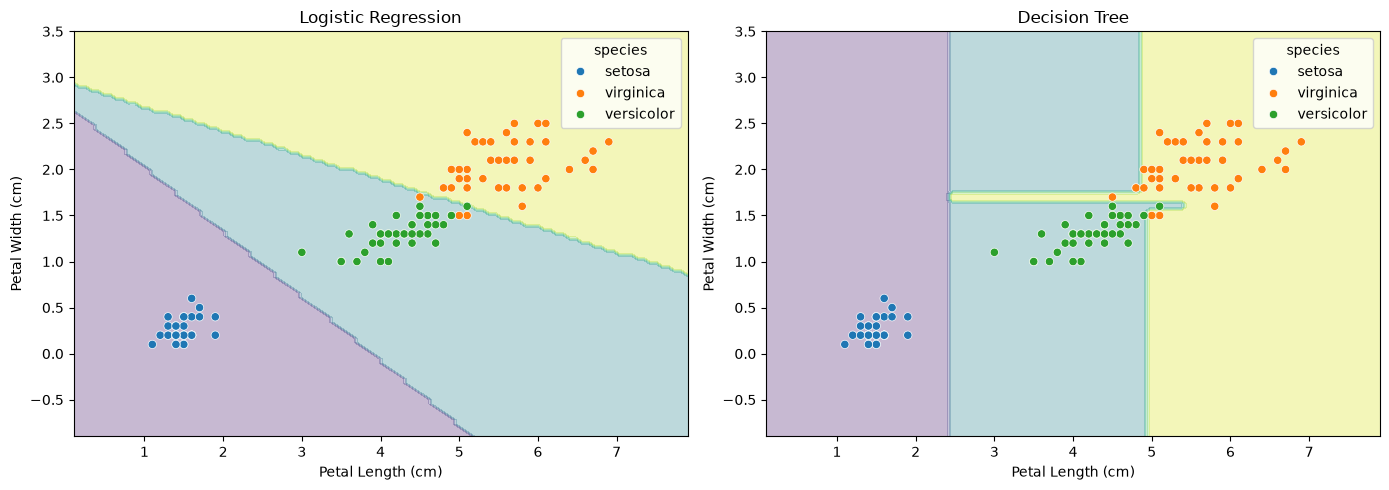

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in [
    (axes[0], lr_2d, "Logistic Regression"),
    (axes[1], tree_2d, "Decision Tree")
]:
    DecisionBoundaryDisplay.from_estimator(
        model,
        X_train_2d,
        response_method="predict",
        plot_method="contourf",
        alpha=0.3,
        ax=ax
    )

    sns.scatterplot(
        data=pd.DataFrame({
            "petal_length": X_train_2d["petal_length"],
            "petal_width": X_train_2d["petal_width"],
            "species": y_train_2d
        }),
        x="petal_length",
        y="petal_width",
        hue="species",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")

plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_tree
}

results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="macro"),
        "Recall": recall_score(y_test, predictions, average="macro"),
        "F1-score": f1_score(y_test, predictions, average="macro")
    })

results_df = pd.DataFrame(results)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


Conclusion

In this project, I developed and compared two machine learning classification models, Logistic Regression and Decision Tree, using the Iris dataset.
The dataset was explored and cleaned before splitting it into training and testing sets using an 80:20 ratio. A Scikit-Learn pipeline with StandardScaler was used for Logistic Regression. Both models were evaluated using accuracy, macro precision, macro recall, macro F1-score, and confusion matrices.
Both models achieved an accuracy of 93.33%, with macro precision, recall, and F1-score also equal to 93.33%. They made the same predictions on the test set, correctly classifying 28 out of 30 observations.
Decision boundary visualizations using petal length and petal width helped illustrate how the two algorithms separate the three Iris species.
These results apply to this particular train-test split. Further evaluation using cross-validation and different splits would help assess how consistently the models perform on unseen data.